# Brain Tumor MRI Dataset Leakage Audit

Checking internal train/test leakage and cross-dataset overlap across 7 public brain tumor datasets, then a patient-level vs naive-split experiment on Figshare.

In [1]:
!pip install imagehash scikit-image opencv-python -q

## 1. Build manifest

In [2]:
import os, csv, hashlib
from PIL import Image
import imagehash

ROOT = "/kaggle/input/datasets/nasiruddin66/brain-tumor-datasets/Brain Tumor Datasets"
OUTPUT_CSV = "/kaggle/working/manifest.csv"

DATASET_FOLDERS = [
    "BDNeuro-HIra", "BRISC", "Br35H", "Brain_Cancer_Mizanur",
    "Masoud Nickparvar", "Shartaj", "figshare"
]
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

def guess_split(parts):
    for p in parts:
        low = p.lower()
        if low in ('train','training'): return 'train'
        if low in ('test','testing'): return 'test'
        if low in ('val','validation'): return 'val'
    return 'none'

def guess_label(parts):
    for p in reversed(parts):
        if p.lower() not in ('train','training','test','testing','val','validation'):
            return p
    return 'unknown'

rows = []
for dataset_name in DATASET_FOLDERS:
    dataset_root = os.path.join(ROOT, dataset_name)
    if not os.path.isdir(dataset_root):
        print(f"missing: {dataset_root}")
        continue
    count_before = len(rows)
    for dirpath, _, files in os.walk(dataset_root):
        for fname in files:
            if not fname.lower().endswith(IMG_EXTS):
                continue
            fpath = os.path.join(dirpath, fname)
            rel = os.path.relpath(fpath, dataset_root)
            parts = rel.split(os.sep)[:-1]
            try:
                img = Image.open(fpath).convert('L')
                rows.append({
                    'dataset': dataset_name, 'filename': fname, 'filepath': fpath,
                    'split': guess_split(parts), 'label': guess_label(parts),
                    'sha256': sha256_of(fpath),
                    'phash': str(imagehash.phash(img)),
                    'dhash': str(imagehash.dhash(img)),
                })
            except Exception as e:
                print(f"skip {fpath}: {e}")
    print(f"{dataset_name}: {len(rows)-count_before} images")

with open(OUTPUT_CSV, 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=rows[0].keys())
    w.writeheader()
    w.writerows(rows)
print(f"\nmanifest saved, {len(rows)} images total")

BDNeuro-HIra: 5941 images
BRISC: 6000 images
Br35H: 3000 images
Brain_Cancer_Mizanur: 6056 images
Masoud Nickparvar: 7200 images
Shartaj: 3264 images
figshare: 3064 images

manifest saved, 34525 images total


In [3]:
import pandas as pd
df = pd.read_csv("/kaggle/working/manifest.csv")
print(df.shape)
print(df.groupby(['dataset','split']).size())

(34525, 8)
dataset               split
BDNeuro-HIra          test      889
                      train    4160
                      val       892
BRISC                 test     1000
                      train    5000
Br35H                 none     3000
Brain_Cancer_Mizanur  none     6056
Masoud Nickparvar     test     1600
                      train    5600
Shartaj               test      394
                      train    2870
figshare              none     3064
dtype: int64


## 2. Internal leakage (train vs test/val, same dataset)

pHash + dHash agreement, Hamming distance <= 8. Preprocessing is consistent within one dataset so this is reliable here - across datasets the crop/contrast/compression differs enough to shift the hash even for identical scans, which is why the cross-dataset check further down uses embeddings instead.

In [4]:
import numpy as np
from scipy.spatial.distance import cdist
import cv2
from skimage.metrics import structural_similarity as ssim

df['phash_bits'] = df['phash'].apply(lambda x: [(int(x,16)>>i)&1 for i in range(64)])
df['dhash_bits'] = df['dhash'].apply(lambda x: [(int(x,16)>>i)&1 for i in range(64)])

def rotation_aware_ssim(path1, path2, size=(256,256)):
    img1 = cv2.imread(path1, cv2.IMREAD_GRAYSCALE)
    img2 = cv2.imread(path2, cv2.IMREAD_GRAYSCALE)
    if img1 is None or img2 is None:
        return None, None
    img1 = cv2.resize(img1, size)
    img2 = cv2.resize(img2, size)
    best, best_o = -1, None
    for angle in [0,90,180,270]:
        if angle == 0: r = img2
        elif angle == 90: r = cv2.rotate(img2, cv2.ROTATE_90_CLOCKWISE)
        elif angle == 180: r = cv2.rotate(img2, cv2.ROTATE_180)
        else: r = cv2.rotate(img2, cv2.ROTATE_90_COUNTERCLOCKWISE)
        flip = cv2.flip(r, 1)
        for variant, label in [(r, f'rot{angle}'), (flip, f'rot{angle}_flip')]:
            s, _ = ssim(img1, variant, full=True)
            if s > best:
                best, best_o = s, label
    return best, best_o

def categorize(s):
    if s is None: return 'unreadable'
    if s >= 0.95: return 'A_true_duplicate'
    if s >= 0.70: return 'B_adjacent_slice'
    return 'C_false_alarm'

def internal_leakage(dataset_name, threshold=8):
    sub = df[df['dataset'] == dataset_name]
    if 'train' not in sub['split'].unique():
        return None
    train = sub[sub['split']=='train'].reset_index(drop=True)
    eval_splits = [s for s in ['test','val'] if s in sub['split'].unique()]

    train_p = np.array(train['phash_bits'].tolist())
    train_d = np.array(train['dhash_bits'].tolist())

    pairs = []
    for split in eval_splits:
        ev = sub[sub['split']==split].reset_index(drop=True)
        ev_p = np.array(ev['phash_bits'].tolist())
        ev_d = np.array(ev['dhash_bits'].tolist())
        pdist = cdist(ev_p, train_p, metric='hamming')*64
        ddist = cdist(ev_d, train_d, metric='hamming')*64
        both = (pdist<=threshold)&(ddist<=threshold)
        for i in range(len(ev)):
            m = np.where(both[i])[0]
            if len(m):
                j = m[0]
                s, o = rotation_aware_ssim(ev.loc[i,'filepath'], train.loc[j,'filepath'])
                pairs.append({'dataset':dataset_name,'eval_split':split,
                              'eval_file':ev.loc[i,'filename'],'eval_path':ev.loc[i,'filepath'],
                              'train_file':train.loc[j,'filename'],'train_path':train.loc[j,'filepath'],
                              'ssim':s,'category':categorize(s)})
    return pd.DataFrame(pairs)

internal_results = []
for name in ["BDNeuro-HIra","BRISC","Masoud Nickparvar","Shartaj"]:
    r = internal_leakage(name)
    if r is not None and len(r):
        internal_results.append(r)
internal_df = pd.concat(internal_results, ignore_index=True)
internal_df.to_csv("/kaggle/working/internal_leakage_final.csv", index=False)

sizes = df[df['split'].isin(['test','val'])].groupby(['dataset','split']).size()
summary = internal_df.groupby(['dataset','eval_split','category']).size().unstack(fill_value=0)
print(sizes)
print()
print(summary)

dataset            split
BDNeuro-HIra       test      889
                   val       892
BRISC              test     1000
Masoud Nickparvar  test     1600
Shartaj            test      394
dtype: int64

category                      A_true_duplicate  B_adjacent_slice  \
dataset           eval_split                                       
BDNeuro-HIra      test                       0                73   
                  val                        1                82   
BRISC             test                      94               154   
Masoud Nickparvar test                     210               326   
Shartaj           test                     222                22   

category                      C_false_alarm  
dataset           eval_split                 
BDNeuro-HIra      test                  245  
                  val                   243  
BRISC             test                  337  
Masoud Nickparvar test                  495  
Shartaj           test                   31

In [5]:
# threshold justification for the internal method (hamming distance + ssim cutoffs)
# same logic as the cosine check below: compare random unrelated pairs against the
# matches the method actually flagged
import random as _random

def hamming_random_baseline(dataset_name, n=300, seed=0):
    sub = df[df['dataset'] == dataset_name]
    if 'train' not in sub['split'].unique():
        return None
    train = sub[sub['split']=='train'].reset_index(drop=True)
    eval_splits = [s for s in ['test','val'] if s in sub['split'].unique()]
    ev = sub[sub['split'].isin(eval_splits)].reset_index(drop=True)
    train_p = np.array(train['phash_bits'].tolist())
    ev_p = np.array(ev['phash_bits'].tolist())
    rng = _random.Random(seed)
    dists = []
    for _ in range(n):
        i = rng.randrange(len(ev_p)); j = rng.randrange(len(train_p))
        dists.append(int((ev_p[i] != train_p[j]).sum()))
    return np.array(dists)

for name in ["BDNeuro-HIra","BRISC","Masoud Nickparvar","Shartaj"]:
    rb = hamming_random_baseline(name)
    if rb is None: continue
    fp_rate = (rb<=8).mean()
    print(f"{name}: random pairs phash hamming -> mean={rb.mean():.1f} median={np.median(rb):.1f} "
          f"5th pct={np.percentile(rb,5):.1f}, false-positive rate at d<=8: {fp_rate:.3%}")

print()
print("ssim score distribution for everything the hashing step flagged as a candidate")
print("(this is what the 0.95 / 0.70 cutoffs are drawn from):")
print(internal_df['ssim'].describe())
print(internal_df['ssim'].quantile([0.1,0.25,0.5,0.75,0.9]))


BDNeuro-HIra: random pairs phash hamming -> mean=27.4 median=28.0 5th pct=18.0, false-positive rate at d<=8: 0.000%
BRISC: random pairs phash hamming -> mean=27.6 median=28.0 5th pct=20.0, false-positive rate at d<=8: 0.000%
Masoud Nickparvar: random pairs phash hamming -> mean=27.2 median=28.0 5th pct=20.0, false-positive rate at d<=8: 0.333%
Shartaj: random pairs phash hamming -> mean=27.9 median=28.0 5th pct=20.0, false-positive rate at d<=8: 0.333%

ssim score distribution for everything the hashing step flagged as a candidate
(this is what the 0.95 / 0.70 cutoffs are drawn from):
count    2535.000000
mean        0.714472
std         0.184210
min         0.100735
25%         0.607566
50%         0.689785
75%         0.819659
max         1.000000
Name: ssim, dtype: float64
0.10    0.508664
0.25    0.607566
0.50    0.689785
0.75    0.819659
0.90    1.000000
Name: ssim, dtype: float64


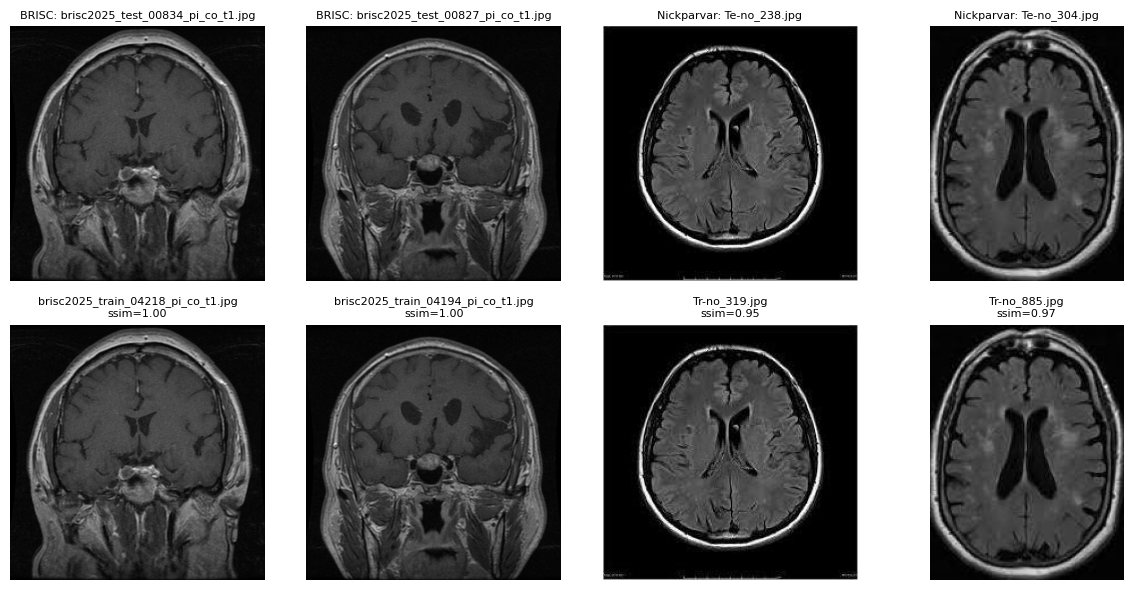

In [6]:
# Fig 1: example internal duplicate pairs (2 from BRISC, 2 from Nickparvar)
import matplotlib.pyplot as plt
from PIL import Image

def show_pairs(frames_with_labels, save_as=None):
    # frames_with_labels: list of (dataset_label, one-row-dataframe-slice)
    n = len(frames_with_labels)
    fig, axes = plt.subplots(2, n, figsize=(3*n, 6))
    if n == 1: axes = axes.reshape(2,1)
    for col, (dname, r) in enumerate(frames_with_labels):
        axes[0,col].imshow(Image.open(r['eval_path']), cmap='gray'); axes[0,col].axis('off')
        axes[0,col].set_title(f"{dname}: {r['eval_file']}", fontsize=8)
        axes[1,col].imshow(Image.open(r['train_path']), cmap='gray'); axes[1,col].axis('off')
        axes[1,col].set_title(f"{r['train_file']}\nssim={r['ssim']:.2f}", fontsize=8)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
    plt.show()

brisc_ex = internal_df[(internal_df['dataset']=='BRISC') & (internal_df['category']=='A_true_duplicate')].head(2)
nick_ex = internal_df[(internal_df['dataset']=='Masoud Nickparvar') & (internal_df['category']=='A_true_duplicate')].head(2)

pairs = [('BRISC', r) for _,r in brisc_ex.iterrows()] + [('Nickparvar', r) for _,r in nick_ex.iterrows()]
show_pairs(pairs, save_as='/kaggle/working/fig1_example_duplicates.png')

## 2.1 Duplicate-corrected retraining (datasets without patient IDs)


In [7]:
# none of these four datasets ship patient or scan IDs, so we can't group folds by
# patient the way the figshare experiment does further down in the notebook. the next best thing:
# use our own duplicate/near-duplicate detections (above) as the grouping signal
# instead. train on the dataset's original split as given, then compare accuracy on the
# full (leaky) eval set against accuracy after removing the eval images our method
# already flagged as a duplicate or adjacent slice of a training image.
#
# this is a proxy for patient-level correction, not a verified one - we have no real
# patient identity to confirm two flagged images are literally the same patient. that
# limitation is noted in the paper. but an image that is near-pixel-identical to a
# training image is not an independent test case regardless of whose scan it is.
#
# matching is done on the full file PATH, not the bare filename - sartaj reuses generic
# names like image(44).jpg independently inside each class folder, so the same filename
# string can legitimately belong to four different images. the path is the only thing
# guaranteed to point at one specific file.
import torch, torchvision.models as models, torchvision.transforms as T
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import norm as _norm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def compute_mean_std_generic(frame, sample_n=500):
    sample = frame.sample(n=min(sample_n,len(frame)), random_state=0)
    pixels = [np.array(Image.open(p).convert('L').resize((224,224)))/255.0 for p in sample['filepath']]
    arr = np.stack(pixels)
    return arr.mean(), arr.std()

class SimpleMRIDataset(Dataset):
    def __init__(self, frame, mean, std, label_map, augment=False):
        self.frame = frame.reset_index(drop=True)
        self.label_map = label_map
        base = [T.Resize((224,224))]
        if augment:
            base += [T.RandomHorizontalFlip(0.5), T.RandomRotation(10), T.ColorJitter(0.1,0.1)]
        base += [T.Grayscale(3), T.ToTensor(), T.Normalize(mean=[mean]*3, std=[std]*3)]
        self.tf = T.Compose(base)
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = Image.open(row['filepath']).convert('L')
        return self.tf(img), self.label_map[row['label']]

def build_simple_model(n_classes):
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    for p in m.parameters():
        p.requires_grad = False
    for p in m.layer4.parameters():
        p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m.to(device)

def train_once(train_df, label_map, epochs=15, lr=1e-4):
    mean, std = compute_mean_std_generic(train_df)
    model = build_simple_model(len(label_map))
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    lossf = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler()

    train_loader = DataLoader(SimpleMRIDataset(train_df, mean, std, label_map, augment=True),
                               batch_size=64, shuffle=True, num_workers=2, pin_memory=True)

    for ep in range(epochs):
        model.train()
        total_loss = 0
        for x,y in train_loader:
            x,y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.cuda.amp.autocast():
                loss = lossf(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            total_loss += loss.item()
        print(f"  epoch {ep+1}/{epochs}  loss={total_loss/len(train_loader):.4f}")

    return model, mean, std

def evaluate(model, eval_df, mean, std, label_map):
    loader = DataLoader(SimpleMRIDataset(eval_df, mean, std, label_map, augment=False),
                         batch_size=64, num_workers=2, pin_memory=True)
    model.eval()
    preds, actual = [], []
    with torch.no_grad():
        for x,y in loader:
            x = x.to(device)
            p = model(x).argmax(1).cpu().numpy()
            preds.extend(p); actual.extend(y.numpy())
    return accuracy_score(actual, preds), f1_score(actual, preds, average='macro'), len(actual)

def two_proportion_ztest(acc_a, n_a, acc_b, n_b):
    correct_a, correct_b = round(acc_a*n_a), round(acc_b*n_b)
    p_pool = (correct_a + correct_b) / (n_a + n_b)
    se = np.sqrt(p_pool*(1-p_pool)*(1/n_a + 1/n_b))
    z = (acc_a - acc_b) / se if se > 0 else 0.0
    p_val = 2*(1 - _norm.cdf(abs(z)))
    return z, p_val

def dedup_correction_check(dataset_name, epochs=15):
    sub = df[df['dataset']==dataset_name].reset_index(drop=True)
    if 'train' not in sub['split'].unique():
        print(f"{dataset_name}: no train split, skipping")
        return None
    train_df = sub[sub['split']=='train'].reset_index(drop=True)
    eval_df = sub[sub['split'].isin(['test','val'])].reset_index(drop=True)
    label_map = {l:i for i,l in enumerate(sorted(sub['label'].unique()))}

    leaked_paths = set(internal_df[(internal_df['dataset']==dataset_name) &
                                    (internal_df['category'].isin(['A_true_duplicate','B_adjacent_slice']))]['eval_path'])
    is_leaked = eval_df['filepath'].isin(leaked_paths)
    clean_eval_df = eval_df[~is_leaked].reset_index(drop=True)
    leaked_eval_df = eval_df[is_leaked].reset_index(drop=True)

    print(f"\n=== {dataset_name}: train={len(train_df)}, full eval={len(eval_df)}, "
          f"corrected eval={len(clean_eval_df)} ({len(leaked_eval_df)} leaked images removed) ===")

    # class balance check - make sure any accuracy change isn't just the corrected set
    # being left with a different (harder or easier) class mix than the full set
    print("  class counts, full eval vs corrected eval:")
    full_counts = eval_df['label'].value_counts()
    clean_counts = clean_eval_df['label'].value_counts()
    for lbl in sorted(label_map):
        print(f"    {lbl}: full={full_counts.get(lbl,0)}  clean={clean_counts.get(lbl,0)}")

    model, mean, std = train_once(train_df, label_map, epochs=epochs)
    acc_full, f1_full, n_full = evaluate(model, eval_df, mean, std, label_map)
    acc_clean, f1_clean, n_clean = evaluate(model, clean_eval_df, mean, std, label_map)

    print(f"  full (leaky) eval:      acc={acc_full:.4f}  f1={f1_full:.4f}  n={n_full}")
    print(f"  corrected (clean) eval: acc={acc_clean:.4f}  f1={f1_clean:.4f}  n={n_clean}")

    z_fc, p_fc = two_proportion_ztest(acc_full, n_full, acc_clean, n_clean)
    print(f"  full vs. clean (clean is a SUBSET of full, not independent - descriptive only): "
          f"z={z_fc:.3f}, p={p_fc:.4f}")

    result = {'dataset':dataset_name, 'n_train':len(train_df), 'n_full_eval':n_full, 'n_clean_eval':n_clean,
              'n_leaked_removed':len(leaked_eval_df), 'acc_full':acc_full, 'acc_clean':acc_clean,
              'f1_full':f1_full, 'f1_clean':f1_clean, 'z_full_vs_clean':z_fc, 'p_full_vs_clean':p_fc}

    # the test that actually matters: leaked-only images vs clean-only images, two
    # disjoint groups from the same model. if leakage inflates the reported number, the
    # leaked group should score noticeably higher - and this can't be waved away as a
    # smaller-sample artifact, since it's two separate groups either way
    if len(leaked_eval_df) >= 10:
        acc_leaked, f1_leaked, n_leaked = evaluate(model, leaked_eval_df, mean, std, label_map)
        z_lc, p_lc = two_proportion_ztest(acc_leaked, n_leaked, acc_clean, n_clean)
        print(f"  leaked-only eval:       acc={acc_leaked:.4f}  f1={f1_leaked:.4f}  n={n_leaked}")
        print(f"  leaked vs. clean (independent groups): z={z_lc:.3f}, p={p_lc:.4f}")
        result.update({'acc_leaked':acc_leaked, 'f1_leaked':f1_leaked, 'n_leaked':n_leaked,
                        'z_leaked_vs_clean':z_lc, 'p_leaked_vs_clean':p_lc})
    else:
        print(f"  too few leaked images ({len(leaked_eval_df)}) for a separate leaked-only accuracy")

    # per-class accuracy, same two groups (full vs clean) - a dataset-level accuracy
    # drop can hide a class that nearly vanished from the corrected set if the leakage
    # filter happened to catch most of one class's test images, so this makes that
    # visible instead of leaving it to be inferred from the class counts above
    def _per_class(frame):
        loader = DataLoader(SimpleMRIDataset(frame, mean, std, label_map, augment=False),
                             batch_size=64, num_workers=2, pin_memory=True)
        model.eval()
        preds, actual = [], []
        with torch.no_grad():
            for x,y in loader:
                x = x.to(device)
                preds.extend(model(x).argmax(1).cpu().numpy()); actual.extend(y.numpy())
        preds, actual = np.array(preds), np.array(actual)
        out = {}
        for lbl, lbl_idx in label_map.items():
            mask = actual == lbl_idx
            n = int(mask.sum())
            out[lbl] = (n, float((preds[mask] == actual[mask]).mean()) if n > 0 else float('nan'))
        return out

    per_class_full = _per_class(eval_df)
    per_class_clean = _per_class(clean_eval_df)
    print("  per-class accuracy, full vs clean eval:")
    for lbl in sorted(label_map):
        fn, facc = per_class_full[lbl]
        cn, cacc = per_class_clean[lbl]
        print(f"    {lbl}: full n={fn} acc={facc:.3f}  |  clean n={cn} acc={cacc:.3f}")
    result['per_class_full'] = per_class_full
    result['per_class_clean'] = per_class_clean

    return result

dedup_results = []
dedup_per_class_rows = []
for name in ["BDNeuro-HIra","BRISC","Masoud Nickparvar","Shartaj"]:
    r = dedup_correction_check(name)
    if r is not None:
        dedup_results.append(r)
        for lbl, (full_n, full_acc) in r.pop('per_class_full').items():
            clean_n, clean_acc = r['per_class_clean'][lbl]
            dedup_per_class_rows.append({'dataset': name, 'label': lbl,
                                          'n_full': full_n, 'acc_full': full_acc,
                                          'n_clean': clean_n, 'acc_clean': clean_acc})
        r.pop('per_class_clean')

dedup_df = pd.DataFrame(dedup_results)
dedup_df.to_csv("/kaggle/working/dedup_correction_check.csv", index=False)
print("\nsummary:")
print(dedup_df)

dedup_per_class_df = pd.DataFrame(dedup_per_class_rows)
dedup_per_class_df.to_csv("/kaggle/working/dedup_per_class_accuracy.csv", index=False)
print("\nper-class accuracy, full vs clean eval (small n for some classes after removing")
print("leaked images - sartaj especially, check n before trusting the accuracy next to it):")
print(dedup_per_class_df)



=== BDNeuro-HIra: train=4160, full eval=1781, corrected eval=1625 (156 leaked images removed) ===
  class counts, full eval vs corrected eval:
    glioma: full=657  clean=577
    meningioma: full=443  clean=423
    notumor: full=236  clean=222
    pituitary: full=445  clean=403
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 228MB/s]
/tmp/ipykernel_49/1915531517.py:60: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_49/1915531517.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.7554
  epoch 2/15  loss=0.3084
  epoch 3/15  loss=0.1930
  epoch 4/15  loss=0.1431
  epoch 5/15  loss=0.1103
  epoch 6/15  loss=0.0766
  epoch 7/15  loss=0.0734
  epoch 8/15  loss=0.0589
  epoch 9/15  loss=0.0552
  epoch 10/15  loss=0.0457
  epoch 11/15  loss=0.0333
  epoch 12/15  loss=0.0315
  epoch 13/15  loss=0.0317
  epoch 14/15  loss=0.0220
  epoch 15/15  loss=0.0254
  full (leaky) eval:      acc=0.9534  f1=0.9502  n=1781
  corrected (clean) eval: acc=0.9532  f1=0.9511  n=1625
  full vs. clean (clean is a SUBSET of full, not independent - descriptive only): z=0.023, p=0.9817
  leaked-only eval:       acc=0.9551  f1=0.9364  n=156
  leaked vs. clean (independent groups): z=0.107, p=0.9145
  per-class accuracy, full vs clean eval:
    glioma: full n=657 acc=0.948  |  clean n=577 acc=0.950
    meningioma: full n=443 acc=0.919  |  clean n=423 acc=0.920
    notumor: full n=236 acc=0.970  |  clean n=222 acc=0.968
    pituitary: full n=445 acc=0.987  |  clean n=403 ac

/tmp/ipykernel_49/1915531517.py:60: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_49/1915531517.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.5502
  epoch 2/15  loss=0.1561
  epoch 3/15  loss=0.1027
  epoch 4/15  loss=0.0837
  epoch 5/15  loss=0.0621
  epoch 6/15  loss=0.0461
  epoch 7/15  loss=0.0354
  epoch 8/15  loss=0.0235
  epoch 9/15  loss=0.0227
  epoch 10/15  loss=0.0266
  epoch 11/15  loss=0.0183
  epoch 12/15  loss=0.0171
  epoch 13/15  loss=0.0152
  epoch 14/15  loss=0.0149
  epoch 15/15  loss=0.0127
  full (leaky) eval:      acc=0.9900  f1=0.9911  n=1000
  corrected (clean) eval: acc=0.9867  f1=0.9872  n=752
  full vs. clean (clean is a SUBSET of full, not independent - descriptive only): z=0.643, p=0.5201
  leaked-only eval:       acc=1.0000  f1=1.0000  n=248
  leaked vs. clean (independent groups): z=1.825, p=0.0680
  per-class accuracy, full vs clean eval:
    glioma: full n=254 acc=0.976  |  clean n=212 acc=0.972
    meningioma: full n=306 acc=0.990  |  clean n=178 acc=0.983
    notumor: full n=140 acc=1.000  |  clean n=140 acc=1.000
    pituitary: full n=300 acc=0.997  |  clean n=222 acc

/tmp/ipykernel_49/1915531517.py:60: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_49/1915531517.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.5123
  epoch 2/15  loss=0.1704
  epoch 3/15  loss=0.1085
  epoch 4/15  loss=0.0838
  epoch 5/15  loss=0.0616
  epoch 6/15  loss=0.0404
  epoch 7/15  loss=0.0441
  epoch 8/15  loss=0.0330
  epoch 9/15  loss=0.0294
  epoch 10/15  loss=0.0277
  epoch 11/15  loss=0.0222
  epoch 12/15  loss=0.0225
  epoch 13/15  loss=0.0196
  epoch 14/15  loss=0.0162
  epoch 15/15  loss=0.0112
  full (leaky) eval:      acc=0.9487  f1=0.9476  n=1600
  corrected (clean) eval: acc=0.9276  f1=0.9156  n=1064
  full vs. clean (clean is a SUBSET of full, not independent - descriptive only): z=2.253, p=0.0242
  leaked-only eval:       acc=0.9907  f1=0.9897  n=536
  leaked vs. clean (independent groups): z=5.397, p=0.0000
  per-class accuracy, full vs clean eval:
    glioma: full n=400 acc=0.818  |  clean n=340 acc=0.791
    meningioma: full n=400 acc=0.980  |  clean n=269 acc=0.981
    notumor: full n=400 acc=1.000  |  clean n=118 acc=1.000
    pituitary: full n=400 acc=0.998  |  clean n=337 ac

/tmp/ipykernel_49/1915531517.py:60: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_49/1915531517.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.8192
  epoch 2/15  loss=0.2899
  epoch 3/15  loss=0.1875
  epoch 4/15  loss=0.1266
  epoch 5/15  loss=0.0909
  epoch 6/15  loss=0.0545
  epoch 7/15  loss=0.0547
  epoch 8/15  loss=0.0454
  epoch 9/15  loss=0.0386
  epoch 10/15  loss=0.0462
  epoch 11/15  loss=0.0331
  epoch 12/15  loss=0.0247
  epoch 13/15  loss=0.0356
  epoch 14/15  loss=0.0391
  epoch 15/15  loss=0.0242
  full (leaky) eval:      acc=0.7817  f1=0.7588  n=394
  corrected (clean) eval: acc=0.4600  f1=0.4394  n=150
  full vs. clean (clean is a SUBSET of full, not independent - descriptive only): z=7.270, p=0.0000
  leaked-only eval:       acc=0.9795  f1=0.9756  n=244
  leaked vs. clean (independent groups): z=12.122, p=0.0000
  per-class accuracy, full vs clean eval:
    glioma: full n=100 acc=0.290  |  clean n=82 acc=0.159
    meningioma: full n=115 acc=0.965  |  clean n=8 acc=0.875
    notumor: full n=105 acc=1.000  |  clean n=8 acc=1.000
    pituitary: full n=74 acc=0.851  |  clean n=52 acc=0.788


## 3. Cross-dataset overlap

pHash/dHash fail here (different crop/contrast/compression per dataset shifts the hash even for identical scans - confirmed this the hard way). Using CNN embedding cosine similarity instead, checked across 4 rotations x flip since some datasets disguise reused images this way.

In [8]:
import torch, torchvision.models as models, torchvision.transforms as T

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
resnet.fc = torch.nn.Identity()
resnet = resnet.to(device).eval()

# second backbone, same frozen/pretrained setup but a different architecture and
# feature size - one network alone doesn't tell us whether the overlap numbers are
# a property of the data or just of resnet50, so we redo it with something else too
densenet = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
densenet.classifier = torch.nn.Identity()
densenet = densenet.to(device).eval()

transform = T.Compose([
    T.Resize((224,224)),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(),
    T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])


cuda
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 200MB/s]


In [9]:
# cache 8-orientation embeddings per dataset, batched for speed. also caches a second
# backbone (densenet121) under a different cache suffix, so the two never overwrite
# each other - used later for the backbone sensitivity check
import os
CACHE_DIR = "/kaggle/working/embeddings_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
BATCH_SIZE = 64

def make_orientations(filepath):
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None: return None
    out = []
    for angle in [0,90,180,270]:
        if angle==0: r = img
        elif angle==90: r = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
        elif angle==180: r = cv2.rotate(img, cv2.ROTATE_180)
        else: r = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)
        flip = cv2.flip(r,1)
        out.append(Image.fromarray(r).convert('RGB'))
        out.append(Image.fromarray(flip).convert('RGB'))
    return out

def cache_embeddings(dataset_name, model=resnet, emb_dim=2048, suffix=''):
    safe = dataset_name.replace(' ','_') + suffix
    emb_path = os.path.join(CACHE_DIR, f"{safe}_emb.npy")
    meta_path = os.path.join(CACHE_DIR, f"{safe}_meta.csv")
    if os.path.exists(emb_path):
        print(f"{dataset_name}{suffix}: already cached")
        return
    sub = df[df['dataset']==dataset_name].reset_index(drop=True)
    n = len(sub)
    all_emb = np.zeros((n,8,emb_dim), dtype=np.float32)
    for start in range(0, n, BATCH_SIZE):
        end = min(start+BATCH_SIZE, n)
        tensors, valid = [], []
        for i in range(start, end):
            variants = make_orientations(sub.loc[i,'filepath'])
            if variants is None:
                valid.append(False); continue
            valid.append(True)
            for v in variants: tensors.append(transform(v))
        if not tensors: continue
        batch = torch.stack(tensors).to(device)
        with torch.no_grad():
            out = model(batch).cpu().numpy()
        idx = 0
        for off, i in enumerate(range(start,end)):
            if valid[off]:
                all_emb[i] = out[idx:idx+8]; idx += 8
        if start % (BATCH_SIZE*10) == 0:
            print(f"  {dataset_name}{suffix}: {end}/{n}")
    np.save(emb_path, all_emb)
    sub.to_csv(meta_path, index=False)
    print(f"{dataset_name}{suffix}: cached {n}")

for name in ["BDNeuro-HIra","BRISC","Br35H","Brain_Cancer_Mizanur",
             "Masoud Nickparvar","Shartaj","figshare"]:
    cache_embeddings(name)

for name in ["BDNeuro-HIra","BRISC","Br35H","Brain_Cancer_Mizanur",
             "Masoud Nickparvar","Shartaj","figshare"]:
    cache_embeddings(name, model=densenet, emb_dim=1024, suffix='_densenet')


  BDNeuro-HIra: 64/5941
  BDNeuro-HIra: 704/5941
  BDNeuro-HIra: 1344/5941
  BDNeuro-HIra: 1984/5941
  BDNeuro-HIra: 2624/5941
  BDNeuro-HIra: 3264/5941
  BDNeuro-HIra: 3904/5941
  BDNeuro-HIra: 4544/5941
  BDNeuro-HIra: 5184/5941
  BDNeuro-HIra: 5824/5941
BDNeuro-HIra: cached 5941
  BRISC: 64/6000
  BRISC: 704/6000
  BRISC: 1344/6000
  BRISC: 1984/6000
  BRISC: 2624/6000
  BRISC: 3264/6000
  BRISC: 3904/6000
  BRISC: 4544/6000
  BRISC: 5184/6000
  BRISC: 5824/6000
BRISC: cached 6000
  Br35H: 64/3000
  Br35H: 704/3000
  Br35H: 1344/3000
  Br35H: 1984/3000
  Br35H: 2624/3000
Br35H: cached 3000
  Brain_Cancer_Mizanur: 64/6056
  Brain_Cancer_Mizanur: 704/6056
  Brain_Cancer_Mizanur: 1344/6056
  Brain_Cancer_Mizanur: 1984/6056
  Brain_Cancer_Mizanur: 2624/6056
  Brain_Cancer_Mizanur: 3264/6056
  Brain_Cancer_Mizanur: 3904/6056
  Brain_Cancer_Mizanur: 4544/6056
  Brain_Cancer_Mizanur: 5184/6056
  Brain_Cancer_Mizanur: 5824/6056
Brain_Cancer_Mizanur: cached 6056
  Masoud Nickparvar: 64/7200


In [10]:
# sanity check: random unrelated pairs should score much lower than real duplicates
from sklearn.metrics.pairwise import cosine_similarity
import random

def load_cached(dataset_name, suffix=''):
    safe = dataset_name.replace(' ','_') + suffix
    emb = np.load(os.path.join(CACHE_DIR, f"{safe}_emb.npy"))
    meta = pd.read_csv(os.path.join(CACHE_DIR, f"{safe}_meta.csv"))
    return emb, meta

def random_baseline(source_name, target_name, n=300):
    src_emb, src_meta = load_cached(source_name)
    tgt_emb, tgt_meta = load_cached(target_name)
    scores = []
    for _ in range(n):
        i = random.randrange(len(src_meta)); j = random.randrange(len(tgt_meta))
        scores.append(cosine_similarity(src_emb[i,0:1], tgt_emb[j,0:1])[0,0])
    return np.array(scores)

# checked across three unrelated pairs instead of one, so the threshold isn't
# resting on a single comparison
baseline_pairs = [("Brain_Cancer_Mizanur","BRISC"),
                   ("BDNeuro-HIra","Masoud Nickparvar"),
                   ("Br35H","Shartaj")]
for src, tgt in baseline_pairs:
    baseline = random_baseline(src, tgt)
    print(f"{src} vs {tgt}: mean={baseline.mean():.3f} median={np.median(baseline):.3f} "
          f"95th pct={np.percentile(baseline,95):.3f} max={baseline.max():.3f}")
print("real duplicates in this study consistently score 0.95+ across all three pairs, so threshold 0.95 is safe")


Brain_Cancer_Mizanur vs BRISC: mean=0.610 median=0.616 95th pct=0.744 max=0.833
BDNeuro-HIra vs Masoud Nickparvar: mean=0.610 median=0.612 95th pct=0.763 max=0.874
Br35H vs Shartaj: mean=0.601 median=0.607 95th pct=0.742 max=0.840
real duplicates in this study consistently score 0.95+ across all three pairs, so threshold 0.95 is safe


In [11]:
COSINE_THRESHOLD = 0.95

def cross_dataset_match(source_name, target_name, thresh=COSINE_THRESHOLD):
    src_emb, src_meta = load_cached(source_name)
    tgt_emb, tgt_meta = load_cached(target_name)
    n_src, n_tgt = len(src_meta), len(tgt_meta)
    src_flat = src_emb.reshape(n_src*8, 2048)
    tgt_flat = tgt_emb.reshape(n_tgt*8, 2048)

    print(f"{source_name} ({n_src}) vs {target_name} ({n_tgt})")
    sim = cosine_similarity(src_flat, tgt_flat).reshape(n_src,8,n_tgt,8).max(axis=(1,3))
    best_idx = sim.argmax(axis=1)
    best_score = sim.max(axis=1)
    mask = best_score >= thresh

    rows = []
    for i in np.where(mask)[0]:
        j = best_idx[i]
        rows.append({'source_dataset':source_name,'target_dataset':target_name,
                      'source_file':src_meta.loc[i,'filename'],'source_path':src_meta.loc[i,'filepath'],
                      'target_file':tgt_meta.loc[j,'filename'],'target_path':tgt_meta.loc[j,'filepath'],
                      'cosine_sim':best_score[i]})
    out = pd.DataFrame(rows)
    print(f"  confirmed: {len(out)}/{n_src} ({100*len(out)/n_src:.2f}%)")
    return out

# direction rule: the SMALLER dataset is always "source" (the one we ask "how much of
# this leaked into the other one"), the LARGER dataset is always "target" - same rule
# for every pair below, so the overlap % is comparable across rows instead of flipping
# with no stated reason
dataset_sizes = df['dataset'].value_counts().to_dict()

PAIRS_UNORDERED = [
    ("Masoud Nickparvar","figshare"), ("BRISC","figshare"),
    ("Shartaj","figshare"), ("Br35H","figshare"),
    ("Br35H","Shartaj"), ("Br35H","Masoud Nickparvar"), ("Br35H","BDNeuro-HIra"),
    ("Brain_Cancer_Mizanur","figshare"), ("Brain_Cancer_Mizanur","Masoud Nickparvar"),
    ("Brain_Cancer_Mizanur","Shartaj"), ("Brain_Cancer_Mizanur","BRISC"), ("Brain_Cancer_Mizanur","Br35H"),
    ("BDNeuro-HIra","figshare"), ("BDNeuro-HIra","Masoud Nickparvar"),
    ("BDNeuro-HIra","Shartaj"), ("BDNeuro-HIra","BRISC"),
]
PAIRS = [tuple(sorted(p, key=lambda name: dataset_sizes[name])) for p in PAIRS_UNORDERED]

cross_results = {}
for src, tgt in PAIRS:
    key = f"{src}__vs__{tgt}"
    cross_results[key] = cross_dataset_match(src, tgt)
    cross_results[key].to_csv(f"/kaggle/working/cross_{key.replace(' ','_')}.csv", index=False)


figshare (3064) vs Masoud Nickparvar (7200)
  confirmed: 3036/3064 (99.09%)
figshare (3064) vs BRISC (6000)
  confirmed: 2874/3064 (93.80%)
figshare (3064) vs Shartaj (3264)
  confirmed: 2304/3064 (75.20%)
Br35H (3000) vs figshare (3064)
  confirmed: 2/3000 (0.07%)
Br35H (3000) vs Shartaj (3264)
  confirmed: 1117/3000 (37.23%)
Br35H (3000) vs Masoud Nickparvar (7200)
  confirmed: 1717/3000 (57.23%)
Br35H (3000) vs BDNeuro-HIra (5941)
  confirmed: 1568/3000 (52.27%)
figshare (3064) vs Brain_Cancer_Mizanur (6056)
  confirmed: 477/3064 (15.57%)
Brain_Cancer_Mizanur (6056) vs Masoud Nickparvar (7200)
  confirmed: 1830/6056 (30.22%)
Shartaj (3264) vs Brain_Cancer_Mizanur (6056)
  confirmed: 709/3264 (21.72%)
BRISC (6000) vs Brain_Cancer_Mizanur (6056)
  confirmed: 1481/6000 (24.68%)
Br35H (3000) vs Brain_Cancer_Mizanur (6056)
  confirmed: 1/3000 (0.03%)
figshare (3064) vs BDNeuro-HIra (5941)
  confirmed: 2420/3064 (78.98%)
BDNeuro-HIra (5941) vs Masoud Nickparvar (7200)
  confirmed: 4250/59

In [12]:
# cross-check: run the same embedding method used for cross-dataset matching on the
# train/eval split within each dataset, as a check on whether hashing alone is
# missing anything internally
def internal_leakage_embeddings(dataset_name, thresh=COSINE_THRESHOLD):
    emb, meta = load_cached(dataset_name)
    if 'train' not in meta['split'].unique():
        return None
    train_idx = meta[meta['split']=='train'].index.to_numpy()
    eval_idx = meta[meta['split'].isin(['test','val'])].index.to_numpy()
    if len(train_idx)==0 or len(eval_idx)==0:
        return None

    train_emb = emb[train_idx].reshape(len(train_idx)*8, 2048)
    eval_emb = emb[eval_idx].reshape(len(eval_idx)*8, 2048)
    sim = cosine_similarity(eval_emb, train_emb).reshape(len(eval_idx),8,len(train_idx),8).max(axis=(1,3))
    best_idx = sim.argmax(axis=1)
    best_score = sim.max(axis=1)
    mask = best_score >= thresh

    rows = []
    for i in np.where(mask)[0]:
        j = best_idx[i]
        rows.append({'dataset': dataset_name,
                      'eval_file': meta.loc[eval_idx[i],'filename'],
                      'eval_split': meta.loc[eval_idx[i],'split'],
                      'train_file': meta.loc[train_idx[j],'filename'],
                      'cosine_sim': best_score[i]})
    out = pd.DataFrame(rows)
    print(f"{dataset_name}: {len(out)}/{len(eval_idx)} eval images matched a training image "
          f"via embeddings ({100*len(out)/len(eval_idx):.1f}%)")
    return out

internal_embedding_results = {}
for name in ["BDNeuro-HIra","BRISC","Masoud Nickparvar","Shartaj"]:
    r = internal_leakage_embeddings(name)
    if r is not None:
        internal_embedding_results[name] = r
        r.to_csv(f"/kaggle/working/internal_embeddings_{name.replace(' ','_')}.csv", index=False)

print()
print("hashing vs embeddings, true-duplicate counts side by side:")
for name in ["BDNeuro-HIra","BRISC","Masoud Nickparvar","Shartaj"]:
    hash_n = internal_df[(internal_df['dataset']==name)&(internal_df['category']=='A_true_duplicate')].shape[0]
    emb_n = len(internal_embedding_results.get(name, []))
    print(f"  {name}: hashing={hash_n}  embeddings={emb_n}")


BDNeuro-HIra: 703/1781 eval images matched a training image via embeddings (39.5%)
BRISC: 620/1000 eval images matched a training image via embeddings (62.0%)
Masoud Nickparvar: 1214/1600 eval images matched a training image via embeddings (75.9%)
Shartaj: 268/394 eval images matched a training image via embeddings (68.0%)

hashing vs embeddings, true-duplicate counts side by side:
  BDNeuro-HIra: hashing=1  embeddings=703
  BRISC: hashing=94  embeddings=620
  Masoud Nickparvar: hashing=210  embeddings=1214
  Shartaj: hashing=222  embeddings=268


## 4. Summary tables

In [13]:
cross_summary = []
for key, r in cross_results.items():
    src, tgt = key.split("__vs__")
    n_src = len(df[df['dataset']==src])
    cross_summary.append({'source':src,'target':tgt,'source_size':n_src,
                           'confirmed_matches':len(r),
                           'pct':round(100*len(r)/n_src,2)})
cross_summary_df = pd.DataFrame(cross_summary).sort_values('pct', ascending=False)
cross_summary_df.to_csv("/kaggle/working/SUMMARY_cross_dataset.csv", index=False)
cross_summary_df

,source,target,source_size,confirmed_matches,pct
0,figshare,Masoud Nickparvar,3064,3036,99.09
1,figshare,BRISC,3064,2874,93.80
14,Shartaj,BDNeuro-HIra,3264,2829,86.67
12,figshare,BDNeuro-HIra,3064,2420,78.98
2,figshare,Shartaj,3064,2304,75.20
13,BDNeuro-HIra,Masoud Nickparvar,5941,4250,71.54
15,BDNeuro-HIra,BRISC,5941,3568,60.06
5,Br35H,Masoud Nickparvar,3000,1717,57.23
6,Br35H,BDNeuro-HIra,3000,1568,52.27
4,Br35H,Shartaj,3000,1117,37.23


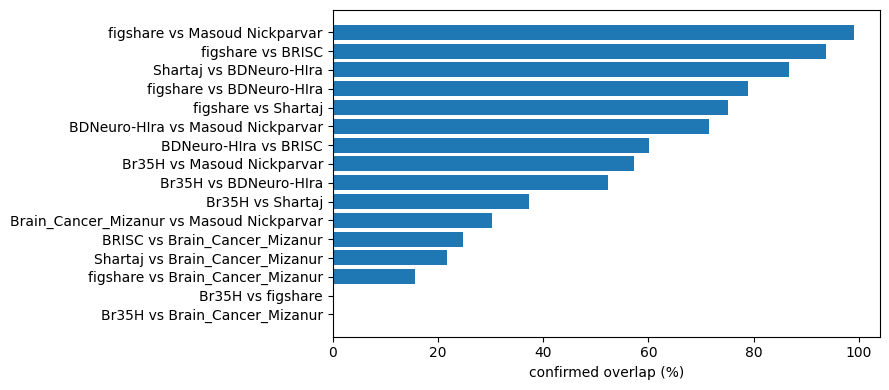

In [14]:
# Fig 2: cross-dataset overlap summary
plt.figure(figsize=(9,4))
ordered = cross_summary_df.sort_values('pct')
plt.barh(ordered['source']+' vs '+ordered['target'], ordered['pct'])
plt.xlabel('confirmed overlap (%)')
plt.tight_layout()
plt.savefig('/kaggle/working/fig2_cross_dataset_overlap.png', dpi=150, bbox_inches='tight')
plt.show()

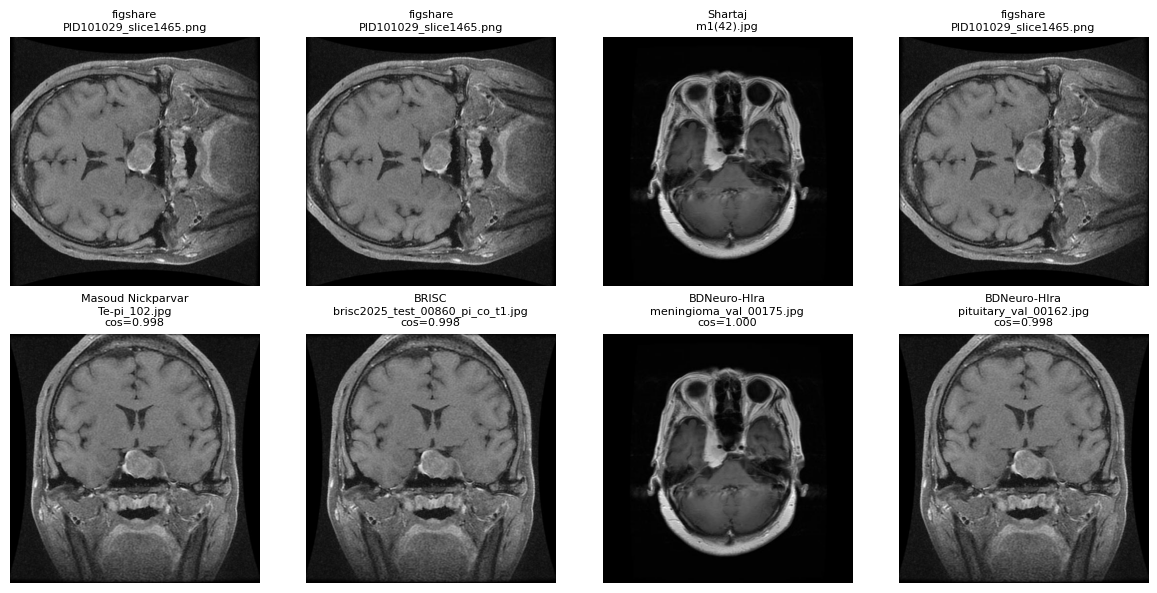

In [15]:
# Fig 2b: example CROSS-DATASET duplicate pairs - the four pairs with the strongest
# overlap, picked automatically so this stays correct no matter which pairs end up on top
def show_cross_examples(examples, save_as=None):
    n = len(examples)
    fig, axes = plt.subplots(2, n, figsize=(3*n, 6))
    if n == 1: axes = axes.reshape(2,1)
    for col, (label, row) in enumerate(examples):
        axes[0,col].imshow(Image.open(row['source_path']), cmap='gray'); axes[0,col].axis('off')
        axes[0,col].set_title(f"{row['source_dataset']}\n{row['source_file']}", fontsize=8)
        axes[1,col].imshow(Image.open(row['target_path']), cmap='gray'); axes[1,col].axis('off')
        axes[1,col].set_title(f"{row['target_dataset']}\n{row['target_file']}\ncos={row['cosine_sim']:.3f}", fontsize=8)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
    plt.show()

top4 = cross_summary_df.sort_values('pct', ascending=False).head(4)
examples = []
for _, row in top4.iterrows():
    key = f"{row['source']}__vs__{row['target']}"
    if key in cross_results and len(cross_results[key]):
        r = cross_results[key].sort_values('cosine_sim', ascending=False).iloc[0]
        examples.append((key, r))

show_cross_examples(examples, save_as='/kaggle/working/fig2b_external_duplicates.png')


In [16]:
internal_summary = internal_df.groupby(['dataset','eval_split','category']).size().unstack(fill_value=0)
internal_summary['eval_size'] = [sizes.get((d,s),0) for d,s in internal_summary.index]
for cat in ['A_true_duplicate','B_adjacent_slice','C_false_alarm']:
    if cat not in internal_summary.columns:
        internal_summary[cat] = 0
    internal_summary[f'{cat}_pct'] = round(100*internal_summary[cat]/internal_summary['eval_size'],2)

# combined total: an adjacent slice is a neighboring scan of the same patient, not an
# independent test case, so it's leakage too - report the combined figure next to the
# category breakdown rather than leaving readers to add the two columns themselves
internal_summary['any_leakage'] = internal_summary['A_true_duplicate'] + internal_summary['B_adjacent_slice']
internal_summary['any_leakage_pct'] = round(100*internal_summary['any_leakage']/internal_summary['eval_size'],2)

internal_summary.to_csv("/kaggle/working/SUMMARY_internal_leakage.csv")
internal_summary


category                      A_true_duplicate  B_adjacent_slice  \
dataset           eval_split                                       
BDNeuro-HIra      test                       0                73   
                  val                        1                82   
BRISC             test                      94               154   
Masoud Nickparvar test                     210               326   
Shartaj           test                     222                22   

category                      C_false_alarm  eval_size  A_true_duplicate_pct  \
dataset           eval_split                                                   
BDNeuro-HIra      test                  245        889                  0.00   
                  val                   243        892                  0.11   
BRISC             test                  337       1000                  9.40   
Masoud Nickparvar test                  495       1600                 13.12   
Shartaj           test                   31        394                 56.35   

category                      B_adjacent_slice_pct  C_false_alarm_pct  \
dataset           eval_split                                            
BDNeuro-HIra      test                        8.21              27.56   
                  val                         9.19              27.24   
BRISC             test                       15.40              33.70   
Masoud Nickparvar test                       20.38              30.94   
Shartaj           test                        5.58               7.87   

category                      any_leakage  any_leakage_pct  
dataset           eval_split                                
BDNeuro-HIra      test                 73             8.21  
                  val                  83             9.30  
BRISC             test                248            24.80  
Masoud Nickparvar test                536            33.50  
Shartaj           test                244            61.93

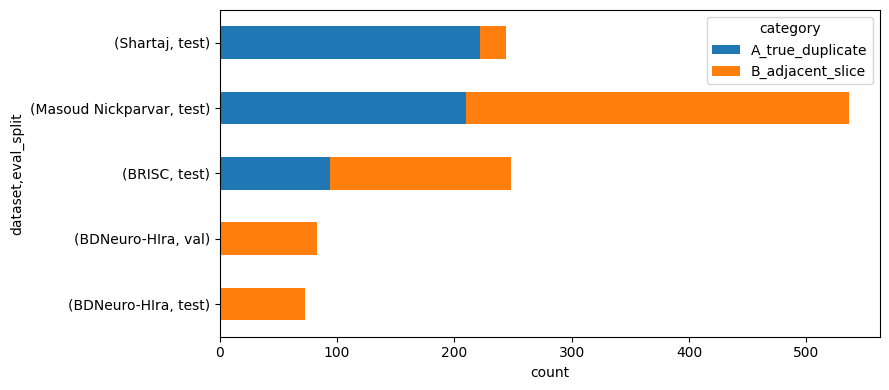

combined leakage (true duplicate + adjacent slice treated as one figure) per dataset/split:
category                      any_leakage  any_leakage_pct
dataset           eval_split                              
BDNeuro-HIra      test                 73             8.21
                  val                  83             9.30
BRISC             test                248            24.80
Masoud Nickparvar test                536            33.50
Shartaj           test                244            61.93


In [17]:
# Fig 3: internal leakage breakdown per dataset
plot_cols = [c for c in ['A_true_duplicate','B_adjacent_slice'] if c in internal_summary.columns]
internal_summary[plot_cols].plot(kind='barh', stacked=True, figsize=(9,4))
plt.xlabel('count')
plt.tight_layout()
plt.savefig('/kaggle/working/fig3_internal_leakage.png', dpi=150, bbox_inches='tight')
plt.show()

print("combined leakage (true duplicate + adjacent slice treated as one figure) per dataset/split:")
print(internal_summary[['any_leakage','any_leakage_pct']])


In [18]:
# backbone sensitivity check: redo the same 16 cross-dataset comparisons using
# densenet121 embeddings instead of resnet50, and see how much the overlap
# percentages actually move
def cross_dataset_match_count(source_name, target_name, suffix, dim, thresh=COSINE_THRESHOLD):
    src_emb, src_meta = load_cached(source_name, suffix)
    tgt_emb, tgt_meta = load_cached(target_name, suffix)
    n_src, n_tgt = len(src_meta), len(tgt_meta)
    src_flat = src_emb.reshape(n_src*8, dim)
    tgt_flat = tgt_emb.reshape(n_tgt*8, dim)
    sim = cosine_similarity(src_flat, tgt_flat).reshape(n_src,8,n_tgt,8).max(axis=(1,3))
    matched = int((sim.max(axis=1) >= thresh).sum())
    return matched, n_src

backbone_rows = []
for src, tgt in PAIRS:
    matched, n_src = cross_dataset_match_count(src, tgt, '_densenet', 1024)
    densenet_pct = round(100*matched/n_src, 2)
    resnet_pct = cross_summary_df.loc[(cross_summary_df['source']==src) &
                                       (cross_summary_df['target']==tgt), 'pct'].values[0]
    backbone_rows.append({'source':src,'target':tgt,'resnet50_pct':resnet_pct,
                           'densenet121_pct':densenet_pct,'abs_diff':round(abs(resnet_pct-densenet_pct),2)})

backbone_df = pd.DataFrame(backbone_rows).sort_values('abs_diff', ascending=False)
backbone_df.to_csv("/kaggle/working/backbone_sensitivity_check.csv", index=False)
print("overlap % by backbone - resnet50 (used throughout the paper) vs densenet121 (sensitivity check):")
print(backbone_df)
print(f"\nmean absolute difference across all {len(backbone_df)} pairs: {backbone_df['abs_diff'].mean():.2f} points, "
      f"max difference: {backbone_df['abs_diff'].max():.2f} points")


overlap % by backbone - resnet50 (used throughout the paper) vs densenet121 (sensitivity check):
                  source                target  resnet50_pct  densenet121_pct  \
8   Brain_Cancer_Mizanur     Masoud Nickparvar         30.22            95.90   
7               figshare  Brain_Cancer_Mizanur         15.57            76.21   
10                 BRISC  Brain_Cancer_Mizanur         24.68            61.75   
9                Shartaj  Brain_Cancer_Mizanur         21.72            56.04   
15          BDNeuro-HIra                 BRISC         60.06            75.64   
13          BDNeuro-HIra     Masoud Nickparvar         71.54            86.38   
12              figshare          BDNeuro-HIra         78.98            91.42   
14               Shartaj          BDNeuro-HIra         86.67            95.47   
4                  Br35H               Shartaj         37.23            45.73   
6                  Br35H          BDNeuro-HIra         52.27            58.10   
2           

In [19]:
# many-to-one check: does a single image get matched by more than one image from
# another dataset, and how many genuinely distinct images are behind all the
# matches combined, rather than just the raw match count per pair
def _find(parent, x):
    while parent[x] != x:
        x = parent[x]
    return x

def _union(parent, a, b):
    ra, rb = _find(parent, a), _find(parent, b)
    if ra != rb:
        parent[ra] = rb

all_cross_matches = pd.concat([v for v in cross_results.values() if len(v)], ignore_index=True)
nodes = set()
for _, r in all_cross_matches.iterrows():
    nodes.add((r['source_dataset'], r['source_file']))
    nodes.add((r['target_dataset'], r['target_file']))

parent = {n: n for n in nodes}
for _, r in all_cross_matches.iterrows():
    _union(parent, (r['source_dataset'], r['source_file']), (r['target_dataset'], r['target_file']))

clusters = {}
for n in nodes:
    clusters.setdefault(_find(parent, n), []).append(n)

cluster_sizes = pd.Series([len(v) for v in clusters.values()])
print(f"total matched images across all 16 pairs: {len(nodes)}")
print(f"unique underlying content clusters: {len(clusters)}  (vs {len(all_cross_matches)} raw pair rows)")
print(f"clusters spanning 3+ images (same content appearing in more than 2 datasets, "
      f"or matched by more than one image): {(cluster_sizes>2).sum()}")
print(cluster_sizes.value_counts().sort_index())


total matched images across all 16 pairs: 24305
unique underlying content clusters: 3721  (vs 30183 raw pair rows)
clusters spanning 3+ images (same content appearing in more than 2 datasets, or matched by more than one image): 3485
2       236
3       453
4       692
5       744
6       294
7       367
8       411
9       232
10       98
11       71
12       31
13       10
14        5
15        9
16        3
17        7
18        3
19        4
20        1
21        1
22        1
24        1
25        2
27        1
28        3
29        2
30        3
31        4
32        2
33        1
34        1
35        3
36        1
37        2
40        1
41        3
42        1
44        1
45        3
47        1
49        2
50        1
53        1
55        1
60        1
64        1
66        1
67        1
72        1
78        1
1552      1
Name: count, dtype: int64


## 5. Manual validation sample

Stratified sample across cosine-similarity bins for 2-rater manual check. Label each pair independently: same image / same slice different look / different slice same scan / different scan. No scores shown while labeling.

In [20]:
all_cross = pd.concat(cross_results.values(), ignore_index=True)

def stratified_sample(df_in, col, bins, n_per_bin, seed=42):
    out = []
    for lo, hi in bins:
        chunk = df_in[(df_in[col]>=lo)&(df_in[col]<hi)]
        out.append(chunk.sample(n=min(n_per_bin,len(chunk)), random_state=seed))
    return pd.concat(out, ignore_index=True)

bins = [(0.95,0.97),(0.97,0.99),(0.99,1.001)]
manual_sample = stratified_sample(all_cross, 'cosine_sim', bins, n_per_bin=25)
manual_sample = manual_sample.sample(frac=1, random_state=1).reset_index(drop=True)  # shuffle
manual_sample['rater1_label'] = ''
manual_sample['rater2_label'] = ''
manual_sample[['source_dataset','target_dataset','source_file','target_file',
               'source_path','target_path','rater1_label','rater2_label']].to_csv(
    "/kaggle/working/MANUAL_VALIDATION_SHEET.csv", index=False)
print(f"{len(manual_sample)} pairs to label -> MANUAL_VALIDATION_SHEET.csv")
print("cosine_sim column intentionally left out of the export so raters aren't biased")

75 pairs to label -> MANUAL_VALIDATION_SHEET.csv
cosine_sim column intentionally left out of the export so raters aren't biased


In [21]:
# below-threshold sample: check whether real duplicates are being missed just under
# the 0.95 cutoff. cross_results only ever kept pairs that already passed the
# threshold, so this reruns the same comparisons and keeps the band just below it instead
def cross_dataset_band(source_name, target_name, lo, hi):
    src_emb, src_meta = load_cached(source_name)
    tgt_emb, tgt_meta = load_cached(target_name)
    n_src, n_tgt = len(src_meta), len(tgt_meta)
    src_flat = src_emb.reshape(n_src*8, 2048)
    tgt_flat = tgt_emb.reshape(n_tgt*8, 2048)
    sim = cosine_similarity(src_flat, tgt_flat).reshape(n_src,8,n_tgt,8).max(axis=(1,3))
    best_idx = sim.argmax(axis=1)
    best_score = sim.max(axis=1)
    mask = (best_score>=lo) & (best_score<hi)

    rows = []
    for i in np.where(mask)[0]:
        j = best_idx[i]
        rows.append({'source_dataset':source_name,'target_dataset':target_name,
                      'source_file':src_meta.loc[i,'filename'],'source_path':src_meta.loc[i,'filepath'],
                      'target_file':tgt_meta.loc[j,'filename'],'target_path':tgt_meta.loc[j,'filepath'],
                      'cosine_sim':best_score[i]})
    return pd.DataFrame(rows)

below_results = []
for src, tgt in PAIRS:
    b = cross_dataset_band(src, tgt, 0.85, 0.95)
    if len(b):
        below_results.append(b)
all_below = pd.concat(below_results, ignore_index=True) if below_results else pd.DataFrame()
print(f"candidates with cosine 0.85-0.95 across all pairs: {len(all_below)}")

below_bins = [(0.85,0.90),(0.90,0.95)]
below_sample = stratified_sample(all_below, 'cosine_sim', below_bins, n_per_bin=25)
below_sample = below_sample.sample(frac=1, random_state=2).reset_index(drop=True)
below_sample['rater1_label'] = ''
below_sample['rater2_label'] = ''
below_sample[['source_dataset','target_dataset','source_file','target_file',
              'source_path','target_path','rater1_label','rater2_label']].to_csv(
    "/kaggle/working/MANUAL_VALIDATION_SHEET_BELOW_THRESHOLD.csv", index=False)
print(f"{len(below_sample)} below-threshold pairs to label -> MANUAL_VALIDATION_SHEET_BELOW_THRESHOLD.csv")
print("cosine_sim left out of the export so raters aren't biased, same as the sheet above")


candidates with cosine 0.85-0.95 across all pairs: 22969
50 below-threshold pairs to label -> MANUAL_VALIDATION_SHEET_BELOW_THRESHOLD.csv
cosine_sim left out of the export so raters aren't biased, same as the sheet above


In [22]:
# same idea for the internal (hashing) method: sample pairs that just missed the
# d<=8 cutoff and check by hand whether any of them are actually duplicates
def internal_leakage_band(dataset_name, lo=9, hi=16):
    sub = df[df['dataset'] == dataset_name]
    if 'train' not in sub['split'].unique():
        return pd.DataFrame()
    train = sub[sub['split']=='train'].reset_index(drop=True)
    eval_splits = [s for s in ['test','val'] if s in sub['split'].unique()]

    pairs = []
    for split in eval_splits:
        ev = sub[sub['split']==split].reset_index(drop=True)
        ev_p = np.array(ev['phash_bits'].tolist())
        ev_d = np.array(ev['dhash_bits'].tolist())
        train_p = np.array(train['phash_bits'].tolist())
        train_d = np.array(train['dhash_bits'].tolist())
        pdist = cdist(ev_p, train_p, metric='hamming')*64
        ddist = cdist(ev_d, train_d, metric='hamming')*64
        # worst of the two hashes - a pair only ever counted as a match if BOTH
        # were small, so this is the natural near-miss measure
        combined = np.maximum(pdist, ddist)
        best_j = combined.argmin(axis=1)
        best_d = combined.min(axis=1)
        band = (best_d>=lo) & (best_d<=hi)
        for i in np.where(band)[0]:
            j = best_j[i]
            pairs.append({'dataset':dataset_name,'eval_split':split,
                          'eval_file':ev.loc[i,'filename'],'eval_path':ev.loc[i,'filepath'],
                          'train_file':train.loc[j,'filename'],'train_path':train.loc[j,'filepath'],
                          'combined_hamming':int(best_d[i])})
    return pd.DataFrame(pairs)

internal_below_results = []
for name in ["BDNeuro-HIra","BRISC","Masoud Nickparvar","Shartaj"]:
    b = internal_leakage_band(name)
    if len(b):
        internal_below_results.append(b)
internal_below = pd.concat(internal_below_results, ignore_index=True) if internal_below_results else pd.DataFrame()
print(f"candidates with combined hamming distance 9-16 across all four datasets: {len(internal_below)}")

internal_below_sample = internal_below.sample(n=min(25,len(internal_below)), random_state=3).reset_index(drop=True)
internal_below_sample['rater1_label'] = ''
internal_below_sample['rater2_label'] = ''
internal_below_sample[['dataset','eval_split','eval_file','train_file','eval_path','train_path',
                        'rater1_label','rater2_label']].to_csv(
    "/kaggle/working/MANUAL_VALIDATION_SHEET_INTERNAL_BELOW.csv", index=False)
print(f"{len(internal_below_sample)} internal below-threshold pairs to label -> MANUAL_VALIDATION_SHEET_INTERNAL_BELOW.csv")


candidates with combined hamming distance 9-16 across all four datasets: 2052
25 internal below-threshold pairs to label -> MANUAL_VALIDATION_SHEET_INTERNAL_BELOW.csv


In [23]:
# Contact sheet: all validation pairs, numbered, source|target side by side.
# Export as PNG pages so your rater can view/print without touching the notebook.

manual_sample = pd.read_csv("/kaggle/working/MANUAL_VALIDATION_SHEET.csv")

def make_contact_sheet(data, page, prefix='validation_sheet_page', per_page=10):
    start = page * per_page
    chunk = data.iloc[start:start+per_page]
    if len(chunk) == 0:
        return
    left_col = 'source_path' if 'source_path' in chunk.columns else 'eval_path'
    right_col = 'target_path' if 'target_path' in chunk.columns else 'train_path'
    fig, axes = plt.subplots(len(chunk), 2, figsize=(6, 2.2*len(chunk)))
    for row, (idx, r) in enumerate(chunk.iterrows()):
        axes[row,0].imshow(Image.open(r[left_col]), cmap='gray'); axes[row,0].axis('off')
        axes[row,1].imshow(Image.open(r[right_col]), cmap='gray'); axes[row,1].axis('off')
        axes[row,0].set_title(f"#{idx}  A", fontsize=9, loc='left')
        axes[row,1].set_title("B", fontsize=9, loc='left')
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/{prefix}{page}.png", dpi=120, bbox_inches='tight')
    plt.close()
    print(f"saved page {page} ({len(chunk)} pairs, #{start}-#{start+len(chunk)-1})")

n_pages = (len(manual_sample) // 10) + 1
for p in range(n_pages):
    make_contact_sheet(manual_sample, p)


saved page 0 (10 pairs, #0-#9)
saved page 1 (10 pairs, #10-#19)
saved page 2 (10 pairs, #20-#29)
saved page 3 (10 pairs, #30-#39)
saved page 4 (10 pairs, #40-#49)
saved page 5 (10 pairs, #50-#59)
saved page 6 (10 pairs, #60-#69)
saved page 7 (5 pairs, #70-#74)


In [24]:
# same contact sheets for the below-threshold cosine sample
n_pages = (len(below_sample) // 10) + 1
for p in range(n_pages):
    make_contact_sheet(below_sample, p, prefix='validation_sheet_below_page')


saved page 0 (10 pairs, #0-#9)
saved page 1 (10 pairs, #10-#19)
saved page 2 (10 pairs, #20-#29)
saved page 3 (10 pairs, #30-#39)
saved page 4 (10 pairs, #40-#49)


In [25]:
# and for the internal below-threshold sample
n_pages = (len(internal_below_sample) // 10) + 1
for p in range(n_pages):
    make_contact_sheet(internal_below_sample, p, prefix='validation_sheet_internal_below_page')


saved page 0 (10 pairs, #0-#9)
saved page 1 (10 pairs, #10-#19)
saved page 2 (5 pairs, #20-#24)


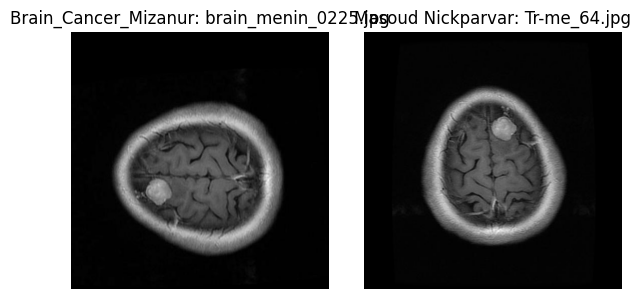

In [26]:
# viewer to go through the sample and fill labels in the sheet by hand afterward
def view_pair(idx):
    r = manual_sample.iloc[idx]
    fig, axes = plt.subplots(1,2,figsize=(6,3))
    axes[0].imshow(Image.open(r['source_path']), cmap='gray'); axes[0].axis('off')
    axes[0].set_title(f"{r['source_dataset']}: {r['source_file']}")
    axes[1].imshow(Image.open(r['target_path']), cmap='gray'); axes[1].axis('off')
    axes[1].set_title(f"{r['target_dataset']}: {r['target_file']}")
    plt.tight_layout(); plt.show()

view_pair(0)

## 6. Figshare patient-level split experiment

Same model, two ways on the same figshare data: a naive random split and a patient-level split, so the gap between them is isolated to the one thing that changed - whether a patient can show up in both train and test. This needs a `PID` recoverable from each figshare filename, so check the pattern below before running the rest.

In [27]:
fig_sample_names = df[df['dataset']=='figshare']['filename'].head(10).tolist()
print(fig_sample_names)
# confirm the PID pattern matches before running the next cell - adjust the regex if not

['PID110993_slice1107.png', 'PID112847_slice1008.png', 'PID105638_slice1764.png', 'PID99223_slice1634.png', 'PID98874_slice1432.png', 'PID97599_slice1595.png', 'PID99223_slice1450.png', 'PID103837_slice1530.png', 'PID112746_slice1258.png', 'PID106062_slice1035.png']


In [28]:
import re

def extract_pid(filename):
    m = re.match(r'^(PID[A-Za-z0-9]+)_slice', filename)
    return m.group(1) if m else None

fig_df = df[df['dataset']=='figshare'].copy()
fig_df['pid'] = fig_df['filename'].apply(extract_pid)

n_unmatched = fig_df['pid'].isna().sum()
n_patients = fig_df['pid'].nunique()
print(f"{n_unmatched} / {len(fig_df)} filenames did not match")
print(f"{n_patients} unique patients")
if n_unmatched > 0:
    print("unmatched examples:", fig_df[fig_df['pid'].isna()]['filename'].head(5).tolist())
assert n_unmatched == 0, "fix the regex before continuing - some filenames did not yield a PID"


0 / 3064 filenames did not match
233 unique patients


In [29]:
# verify: no patient ever appears in both train and test of the same fold
from sklearn.model_selection import GroupKFold

_gkf_check = GroupKFold(n_splits=5)
for fold, (tr_idx, te_idx) in enumerate(_gkf_check.split(fig_df, groups=fig_df['pid'])):
    train_pids = set(fig_df.iloc[tr_idx]['pid'])
    test_pids = set(fig_df.iloc[te_idx]['pid'])
    overlap = train_pids & test_pids
    print(f"fold {fold}: train patients={len(train_pids)}  test patients={len(test_pids)}  overlap={len(overlap)}")
    assert len(overlap) == 0, f"leak detected in fold {fold}"
print("confirmed: patient-level split is clean across all folds")

fold 0: train patients=187  test patients=46  overlap=0
fold 1: train patients=186  test patients=47  overlap=0
fold 2: train patients=186  test patients=47  overlap=0
fold 3: train patients=186  test patients=47  overlap=0
fold 4: train patients=187  test patients=46  overlap=0
confirmed: patient-level split is clean across all folds


In [30]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupKFold, StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import time

label_map = {l:i for i,l in enumerate(sorted(fig_df['label'].unique()))}
fig_df['y'] = fig_df['label'].map(label_map)

def compute_mean_std(frame, sample_n=500):
    sample = frame.sample(n=min(sample_n,len(frame)), random_state=0)
    pixels = [np.array(Image.open(p).convert('L').resize((224,224)))/255.0 for p in sample['filepath']]
    arr = np.stack(pixels)
    return arr.mean(), arr.std()

class MRIDataset(Dataset):
    def __init__(self, frame, mean, std, augment=False):
        self.frame = frame.reset_index(drop=True)
        base = [T.Resize((224,224))]
        if augment:
            base += [T.RandomHorizontalFlip(0.5), T.RandomRotation(10), T.ColorJitter(0.1,0.1)]
        base += [T.Grayscale(3), T.ToTensor(), T.Normalize(mean=[mean]*3, std=[std]*3)]
        self.tf = T.Compose(base)
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = Image.open(row['filepath']).convert('L')
        return self.tf(img), row['y']

def build_model(n_classes):
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    for p in m.parameters():
        p.requires_grad = False
    for p in m.layer4.parameters():
        p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m.to(device)

def train_and_eval(train_df, test_df, epochs=15, lr=1e-4):
    # mean/std come from this fold's training images only. computing them from the
    # whole dataset once (like before) puts test-image statistics into every fold's
    # normalization, which is its own small leak
    mean, std = compute_mean_std(train_df)

    n_classes = fig_df['y'].nunique()
    model = build_model(n_classes)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    lossf = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler()

    train_loader = DataLoader(MRIDataset(train_df, mean, std, augment=True), batch_size=64, shuffle=True,
                               num_workers=2, pin_memory=True)
    test_loader = DataLoader(MRIDataset(test_df, mean, std, augment=False), batch_size=64,
                              num_workers=2, pin_memory=True)

    for ep in range(epochs):
        t0 = time.time()
        model.train()
        total_loss = 0
        for x,y in train_loader:
            x,y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.cuda.amp.autocast():
                loss = lossf(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            total_loss += loss.item()
        print(f"  epoch {ep+1}/{epochs}  loss={total_loss/len(train_loader):.4f}  ({time.time()-t0:.0f}s)")

    model.eval()
    preds, actual = [], []
    with torch.no_grad():
        for x,y in test_loader:
            x = x.to(device)
            p = model(x).argmax(1).cpu().numpy()
            preds.extend(p); actual.extend(y.numpy())

    return {
        'acc': accuracy_score(actual, preds),
        'f1_macro': f1_score(actual, preds, average='macro'),
        'cm': confusion_matrix(actual, preds),
        'report': classification_report(actual, preds, target_names=list(label_map.keys()), output_dict=True),
        'norm_mean': mean, 'norm_std': std,
    }


In [31]:
def fold_class_counts(frame, idx):
    return frame.iloc[idx]['label'].value_counts().reindex(sorted(label_map.keys())).to_dict()

def run_kfold(strategy, n_splits=5, epochs=15):
    results = []
    if strategy == 'patient':
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42).split(
            fig_df, fig_df['y'], groups=fig_df['pid'])
    else:
        splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42).split(fig_df, fig_df['y'])

    for fold, (tr_idx, te_idx) in enumerate(splitter):
        print(f"fold {fold}:")
        print(f"  train class counts: {fold_class_counts(fig_df, tr_idx)}")
        print(f"  test class counts:  {fold_class_counts(fig_df, te_idx)}")
        r = train_and_eval(fig_df.iloc[tr_idx], fig_df.iloc[te_idx], epochs=epochs)
        r['fold'] = fold
        results.append(r)
        print(f"  -> acc={r['acc']:.4f} f1={r['f1_macro']:.4f}")
    return results

print("=== naive split (Stratified K-Fold, patient identity ignored) ===")
naive_results = run_kfold('naive')

print("\n=== patient split (Stratified Group K-Fold - patients disjoint, classes balanced per fold) ===")
patient_results = run_kfold('patient')

naive_accs = [r['acc'] for r in naive_results]
patient_accs = [r['acc'] for r in patient_results]
print(f"\nnaive:   {np.mean(naive_accs):.4f} +/- {np.std(naive_accs):.4f}")
print(f"patient: {np.mean(patient_accs):.4f} +/- {np.std(patient_accs):.4f}")
print(f"gap: {100*(np.mean(naive_accs)-np.mean(patient_accs)):.2f} points")

# paired test across the 5 matched folds. wilcoxon signed-rank isn't useful with only
# 5 pairs - its smallest possible two-sided p-value is 0.0625, so it can never reach
# significance here no matter how consistent the gap is. a paired t-test on the
# fold-level accuracies is the right tool at this sample size.
from scipy import stats
diffs = np.array(naive_accs) - np.array(patient_accs)
t_stat, p_val = stats.ttest_rel(naive_accs, patient_accs)
ci_lo, ci_hi = stats.t.interval(0.95, df=len(diffs)-1, loc=diffs.mean(), scale=stats.sem(diffs))
print(f"\npaired t-test: t={t_stat:.3f}, p={p_val:.4f}")
print(f"95% CI on mean accuracy difference: [{ci_lo*100:.2f}, {ci_hi*100:.2f}] points")


=== naive split (Stratified K-Fold, patient identity ignored) ===
fold 0:
  train class counts: {'glioma': 1141, 'meningioma': 566, 'pituitary': 744}
  test class counts:  {'glioma': 285, 'meningioma': 142, 'pituitary': 186}


/tmp/ipykernel_49/1678898983.py:49: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_49/1678898983.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.6783  (13s)
  epoch 2/15  loss=0.2697  (11s)
  epoch 3/15  loss=0.1800  (11s)
  epoch 4/15  loss=0.1467  (11s)
  epoch 5/15  loss=0.1160  (11s)
  epoch 6/15  loss=0.0832  (11s)
  epoch 7/15  loss=0.0711  (11s)
  epoch 8/15  loss=0.0585  (11s)
  epoch 9/15  loss=0.0642  (12s)
  epoch 10/15  loss=0.0383  (11s)
  epoch 11/15  loss=0.0412  (11s)
  epoch 12/15  loss=0.0458  (11s)
  epoch 13/15  loss=0.0376  (11s)
  epoch 14/15  loss=0.0319  (11s)
  epoch 15/15  loss=0.0360  (11s)
  -> acc=0.9723 f1=0.9681
fold 1:
  train class counts: {'glioma': 1141, 'meningioma': 566, 'pituitary': 744}
  test class counts:  {'glioma': 285, 'meningioma': 142, 'pituitary': 186}


/tmp/ipykernel_49/1678898983.py:49: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_49/1678898983.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.6171  (11s)
  epoch 2/15  loss=0.2430  (11s)
  epoch 3/15  loss=0.1857  (11s)
  epoch 4/15  loss=0.1331  (11s)
  epoch 5/15  loss=0.1148  (11s)
  epoch 6/15  loss=0.0903  (11s)
  epoch 7/15  loss=0.0771  (11s)
  epoch 8/15  loss=0.0568  (11s)
  epoch 9/15  loss=0.0576  (11s)
  epoch 10/15  loss=0.0531  (11s)
  epoch 11/15  loss=0.0465  (11s)
  epoch 12/15  loss=0.0418  (11s)
  epoch 13/15  loss=0.0276  (11s)
  epoch 14/15  loss=0.0214  (11s)
  epoch 15/15  loss=0.0276  (11s)
  -> acc=0.9576 f1=0.9502
fold 2:
  train class counts: {'glioma': 1141, 'meningioma': 566, 'pituitary': 744}
  test class counts:  {'glioma': 285, 'meningioma': 142, 'pituitary': 186}


...

  epoch 1/15  loss=0.6659  (11s)
  epoch 2/15  loss=0.2681  (11s)
  epoch 3/15  loss=0.1807  (11s)
  epoch 4/15  loss=0.1506  (11s)
  epoch 5/15  loss=0.0979  (11s)
  epoch 6/15  loss=0.0757  (11s)
  epoch 7/15  loss=0.0694  (11s)
  epoch 8/15  loss=0.0557  (11s)
  epoch 9/15  loss=0.0494  (11s)
  epoch 10/15  loss=0.0586  (11s)
  epoch 11/15  loss=0.0396  (11s)
  epoch 12/15  loss=0.0273  (12s)
  epoch 13/15  loss=0.0274  (11s)
  epoch 14/15  loss=0.0228  (11s)
  epoch 15/15  loss=0.0292  (11s)
  -> acc=0.9635 f1=0.9596
fold 3:
  train class counts: {'glioma': 1088, 'meningioma': 576, 'pituitary': 715}
  test class counts:  {'glioma': 338, 'meningioma': 132, 'pituitary': 215}


/tmp/ipykernel_49/1678898983.py:49: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_49/1678898983.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.6594  (11s)
  epoch 2/15  loss=0.2577  (11s)
  epoch 3/15  loss=0.1640  (11s)
  epoch 4/15  loss=0.1227  (11s)
  epoch 5/15  loss=0.1019  (11s)
  epoch 6/15  loss=0.0892  (11s)
  epoch 7/15  loss=0.0522  (11s)
  epoch 8/15  loss=0.0547  (11s)
  epoch 9/15  loss=0.0527  (11s)
  epoch 10/15  loss=0.0574  (11s)
  epoch 11/15  loss=0.0396  (11s)
  epoch 12/15  loss=0.0358  (11s)
  epoch 13/15  loss=0.0294  (11s)
  epoch 14/15  loss=0.0259  (11s)
  epoch 15/15  loss=0.0244  (11s)
  -> acc=0.9007 f1=0.8841
fold 4:
  train class counts: {'glioma': 1102, 'meningioma': 578, 'pituitary': 788}
  test class counts:  {'glioma': 324, 'meningioma': 130, 'pituitary': 142}


/tmp/ipykernel_49/1678898983.py:49: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_49/1678898983.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  epoch 1/15  loss=0.6535  (11s)
  epoch 2/15  loss=0.2494  (12s)
  epoch 3/15  loss=0.1842  (11s)
  epoch 4/15  loss=0.1414  (12s)
  epoch 5/15  loss=0.0922  (12s)
  epoch 6/15  loss=0.0829  (12s)
  epoch 7/15  loss=0.0818  (12s)
  epoch 8/15  loss=0.0575  (12s)
  epoch 9/15  loss=0.0484  (12s)
  epoch 10/15  loss=0.0315  (12s)
  epoch 11/15  loss=0.0299  (12s)
  epoch 12/15  loss=0.0337  (12s)
  epoch 13/15  loss=0.0305  (11s)
  epoch 14/15  loss=0.0266  (11s)
  epoch 15/15  loss=0.0214  (11s)
  -> acc=0.9312 f1=0.9261

naive:   0.9710 +/- 0.0069
patient: 0.9182 +/- 0.0277
gap: 5.27 points

paired t-test: t=4.728, p=0.0091
95% CI on mean accuracy difference: [2.18, 8.37] points


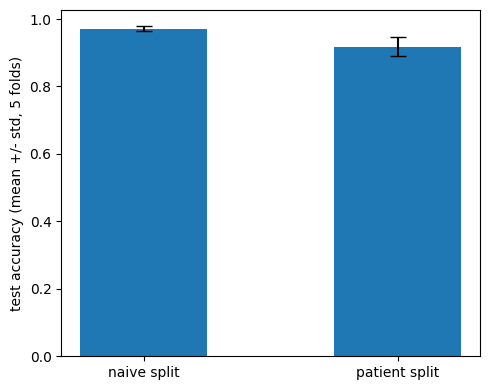

In [32]:
# Fig 4: naive vs patient split accuracy
plt.figure(figsize=(5,4))
plt.bar(['naive split','patient split'],
        [np.mean(naive_accs), np.mean(patient_accs)],
        yerr=[np.std(naive_accs), np.std(patient_accs)], capsize=6, width=0.5)
plt.ylabel('test accuracy (mean +/- std, 5 folds)')
plt.tight_layout()
plt.savefig('/kaggle/working/fig4_split_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

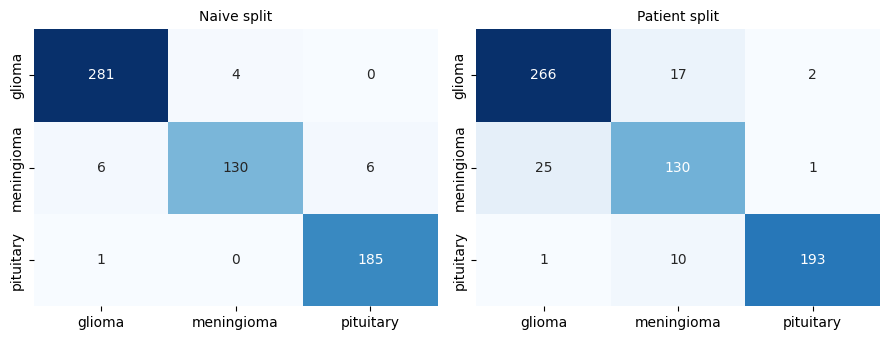

In [33]:
# Fig 5: confusion matrices, fold 0 of each strategy
import seaborn as sns

labels = list(label_map.keys())
fig, axes = plt.subplots(1,2, figsize=(9,3.5))
sns.heatmap(naive_results[0]['cm'], annot=True, fmt='d', xticklabels=labels, yticklabels=labels, ax=axes[0], cmap='Blues', cbar=False)
axes[0].set_title('Naive split', fontsize=10)
sns.heatmap(patient_results[0]['cm'], annot=True, fmt='d', xticklabels=labels, yticklabels=labels, ax=axes[1], cmap='Blues', cbar=False)
axes[1].set_title('Patient split', fontsize=10)
plt.tight_layout()
plt.savefig('/kaggle/working/fig5_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [34]:
import json as _json

def avg_report_across_folds(results):
    reports = [r['report'] for r in results]
    classes = list(label_map.keys())
    rows = []
    for cls in classes:
        precisions = [r[cls]['precision'] for r in reports]
        recalls = [r[cls]['recall'] for r in reports]
        f1s = [r[cls]['f1-score'] for r in reports]
        rows.append({
            'class': cls,
            'precision_mean': np.mean(precisions), 'precision_std': np.std(precisions),
            'recall_mean': np.mean(recalls), 'recall_std': np.std(recalls),
            'f1_mean': np.mean(f1s), 'f1_std': np.std(f1s),
        })
    return pd.DataFrame(rows)

naive_class_metrics = avg_report_across_folds(naive_results)
patient_class_metrics = avg_report_across_folds(patient_results)

naive_class_metrics.to_csv("/kaggle/working/naive_per_class_metrics.csv", index=False)
patient_class_metrics.to_csv("/kaggle/working/patient_per_class_metrics.csv", index=False)

with open('/kaggle/working/naive_report_fold0.json','w') as f:
    _json.dump(naive_results[0]['report'], f, indent=2)
with open('/kaggle/working/patient_report_fold0.json','w') as f:
    _json.dump(patient_results[0]['report'], f, indent=2)

print("naive split - per class (mean +/- std over 5 folds)")
print(naive_class_metrics)
print("\npatient split - per class (mean +/- std over 5 folds)")
print(patient_class_metrics)
print("\nTable 4 should pull from these two CSVs now, not the fold0 json files -")
print("those are kept only as a raw per-fold reference, not for the paper's summary numbers.")


naive split - per class (mean +/- std over 5 folds)
        class  precision_mean  precision_std  recall_mean  recall_std  \
0      glioma        0.982778       0.015337     0.976876    0.014251   
1  meningioma        0.947208       0.023409     0.936520    0.044304   
2   pituitary        0.972601       0.012151     0.988172    0.009250   

    f1_mean    f1_std  
0  0.979619  0.005125  
1  0.940731  0.015788  
2  0.980283  0.008691  

patient split - per class (mean +/- std over 5 folds)
        class  precision_mean  precision_std  recall_mean  recall_std  \
0      glioma        0.951952       0.024665     0.923491    0.031570   
1  meningioma        0.810812       0.070218     0.873980    0.057642   
2   pituitary        0.961686       0.044305     0.945014    0.029484   

    f1_mean    f1_std  
0  0.937220  0.023593  
1  0.839488  0.054220  
2  0.952328  0.023930  

Table 4 should pull from these two CSVs now, not the fold0 json files -
those are kept only as a raw per-fold refe

## 7. Zip everything for download

In [35]:
import shutil, os

FILES_TO_ZIP = [
    "manifest.csv",
    "internal_leakage_final.csv",
    "SUMMARY_internal_leakage.csv",
    "SUMMARY_cross_dataset.csv",
    "MANUAL_VALIDATION_SHEET.csv",
    "MANUAL_VALIDATION_SHEET_BELOW_THRESHOLD.csv",
    "MANUAL_VALIDATION_SHEET_INTERNAL_BELOW.csv",
    "dedup_correction_check.csv",
    "dedup_per_class_accuracy.csv",
    "backbone_sensitivity_check.csv",
    "naive_report_fold0.json",
    "patient_report_fold0.json",
    "naive_per_class_metrics.csv",
    "patient_per_class_metrics.csv",
    "fig1_example_duplicates.png",
    "fig2b_external_duplicates.png",
    "fig2_cross_dataset_overlap.png",
    "fig3_internal_leakage.png",
    "fig4_split_comparison.png",
    "fig5_confusion_matrices.png",
]

# all the individual cross-dataset comparison CSVs, the internal-embeddings cross-check
# CSVs, and every contact-sheet page (original + both below-threshold sets)
cross_csvs = [f for f in os.listdir("/kaggle/working") if f.startswith("cross_") and f.endswith(".csv")]
embedding_csvs = [f for f in os.listdir("/kaggle/working") if f.startswith("internal_embeddings_") and f.endswith(".csv")]
contact_sheets = [f for f in os.listdir("/kaggle/working") if f.startswith("validation_sheet") and f.endswith(".png")]

ZIP_DIR = "/kaggle/working/paper_outputs"
os.makedirs(ZIP_DIR, exist_ok=True)

all_files = FILES_TO_ZIP + cross_csvs + embedding_csvs + contact_sheets
copied, missing = [], []
for fname in all_files:
    src = os.path.join("/kaggle/working", fname)
    if os.path.exists(src):
        shutil.copy(src, os.path.join(ZIP_DIR, fname))
        copied.append(fname)
    else:
        missing.append(fname)

shutil.make_archive("/kaggle/working/brain_tumor_leakage_audit_outputs", 'zip', ZIP_DIR)

print(f"zipped {len(copied)} files -> brain_tumor_leakage_audit_outputs.zip")
if missing:
    print(f"not found (run the earlier cells first if these are missing): {missing}")


zipped 56 files -> brain_tumor_leakage_audit_outputs.zip
